## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
from pathlib import Path

data_path = next(
    (path for path in (Path('data/ff_market_daily.parquet'),
                       Path('ff_market_daily.parquet'),
                       Path('../data/ff_market_daily.parquet'))
     if path.is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError('Could not find ff_market_daily.parquet from the current working directory.')

df = pd.read_parquet(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

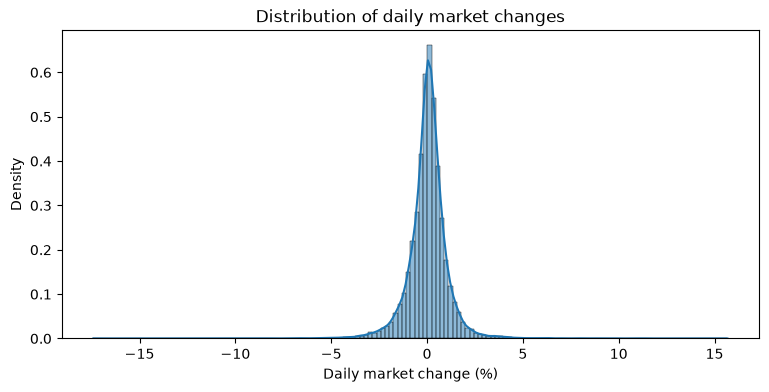

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

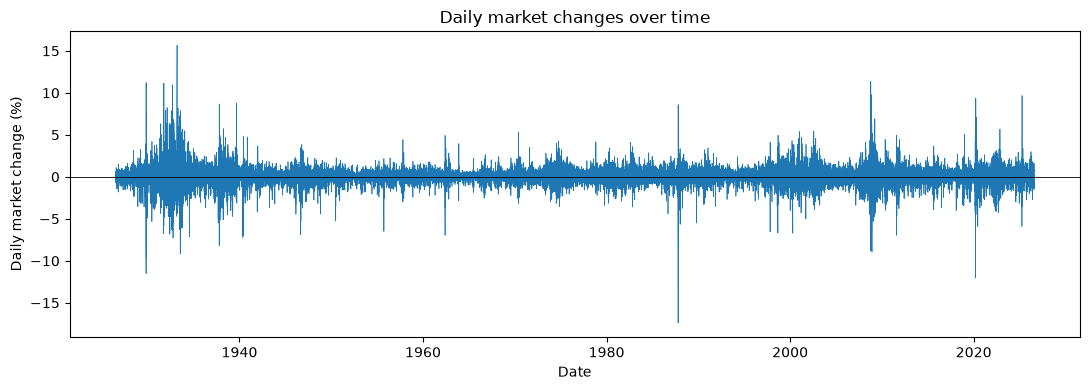

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [11]:
df["current value"] = df["market_return_pct"]
df["next value"] = df["market_return_pct"].shift(-1)

pairs = df.dropna(subset=["next value"]).copy()

pairs["today category"] = np.where(pairs["current value"] > 0, "up", "down")
pairs["tomorrow category"] = np.where(pairs["next value"] > 0, "up", "down")





In [12]:
joint_counts = pd.crosstab(pairs["today category"], pairs["tomorrow category"], normalize=True)
joint_counts


tomorrow category,down,up
today category,,
down,0.224720,0.228142
up,0.228142,0.318996


In [13]:

marginals = pd.crosstab(pairs["today category"], pairs["tomorrow category"], normalize=True, margins=True)
marginals

tomorrow category,down,up,All
today category,,,
down,0.224720,0.228142,0.452862
up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [14]:
conditional_counts = pd.crosstab(pairs["today category"], pairs["tomorrow category"], normalize='index')
conditional_counts

tomorrow category,down,up
today category,,
down,0.496221,0.503779
up,0.416974,0.583026


Up transitions are more common than down transitions. We are more likely to transition to an Up day from an Up day than a Down day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [19]:
df['market_bin'] = pd.cut(df['market_return_pct'], bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain'])
df["current value"] = df["market_bin"]
df["next value"] = df["market_bin"].shift(-1)
df['market_bin'].value_counts().sort_index()

market_bin
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

2759 days fall under large loss, 7452 days fall under small loss, 3441 falls under near zero, 9785 days fall under small gain, and 2859 days fall under large gain. The most common is small gain and least common is large loss.

In [27]:
joint_tab = pd.crosstab(df['current value'], df['next value'],
            normalize=True)
joint_tab

next value,Large loss,Small loss,Near zero,Small gain,Large gain
current value,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


In [28]:
marginal = pd.crosstab(df['current value'], df['next value'],
            normalize=True, margins=True)
marginal

next value,Large loss,Small loss,Near zero,Small gain,Large gain,All
current value,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


The transitions most likely to occur are small gain to small gain and small gain to small loss.

In [26]:
conditional_tab = pd.crosstab(df['current value'], df['next value'],
            normalize='index')
conditional_tab

next value,Large loss,Small loss,Near zero,Small gain,Large gain
current value,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


For large loss, the most likely future states are small loss and small gain. For small loss, the most likely future states are small gain and small loss. For near zero, the most likely future states are small gain and small loss. For small gain, the most likely future states are small loss and small gain. For large gain, the most likely future states are small gain and small loss. 

The conditional distribution is not uniform. The small gain probability ranges from 0.067 to 0.428, large loss from 0.086 to 0.264, small loss from 0.096 to 0.345, near zero from 0.070 to 0.376, and large gain from 0.107 to 0.347. Small gain and small loss are more likely than 0.2 while the rest are less likely, indicating some predicive pattern but with some uncertainty on the next state.



In [29]:
df['market_return_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('current value', observed=False)['market_return_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
current value,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


The expected returns for tomorrow range from -0.0383 to 0.163. The largest standard deviations are large loss, indicating higher volatility for larger moves in loss and gain. The minimum and maximum very with minimum ranging from -17.41 to -8.19 and maximum from 5.49 to 15.67, indicating large variation beteen states that is greater with larger moves.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [30]:
df['current value'] = pd.qcut(df['market_return_pct'], q=21, labels=False)
df['next value'] = df['current value'].shift(-1)

df = df.dropna(subset=["next value"]).copy()

[Text(0.5, 1.0, 'Joint PMF')]

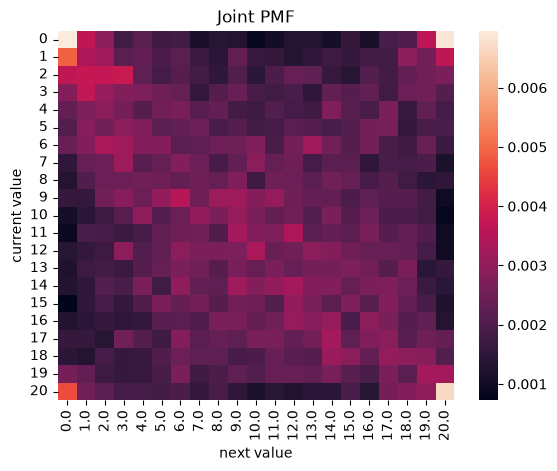

In [31]:
joint_tab = pd.crosstab(df['current value'], df['next value'],
            normalize=True)
sns.heatmap(joint_tab).set(title='Joint PMF')

The heatmap shows there are brighter cells in the more extreme bins for smallest and highest values, indiciating a higher probability of extreme values occuring the next day if there was an extreme value in the current day, but the exact direction being uncertain.

[Text(0.5, 1.0, 'Conditional PMF')]

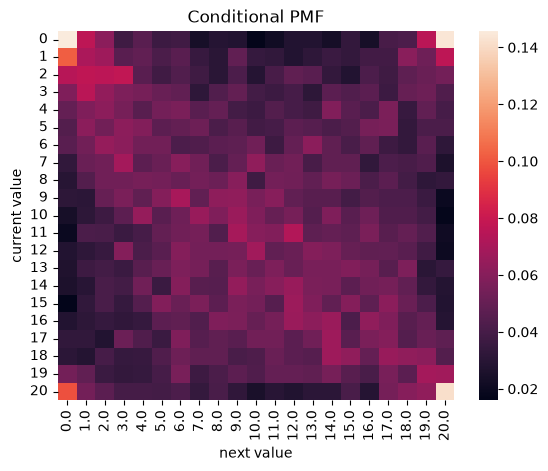

In [32]:
conditional_pmf = pd.crosstab(df['current value'], df['next value'],
            normalize='index')
sns.heatmap(conditional_pmf).set(title='Conditional PMF')

Much like joint probability, extreme values in the current day lead to extreme values in the next day, but the value being lower or higher is uncertain.

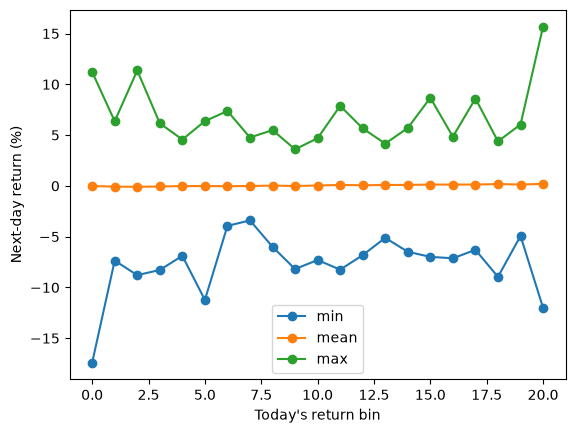

In [34]:
df['market_return_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('current value', observed=False)['market_return_tp1'].agg(['min','mean','max']).plot(marker='o')
plt.ylabel("Next-day return (%)")
plt.xlabel("Today's return bin")
plt.show()

The mean is consistently near zero average across all of the bins. The minimum has its largest next day return losses in the extreme values and maximum has the largest next day return gains in extreme values. The next day returns tend to have the highest decrease or increase in minimum and maximum at the extreme values.

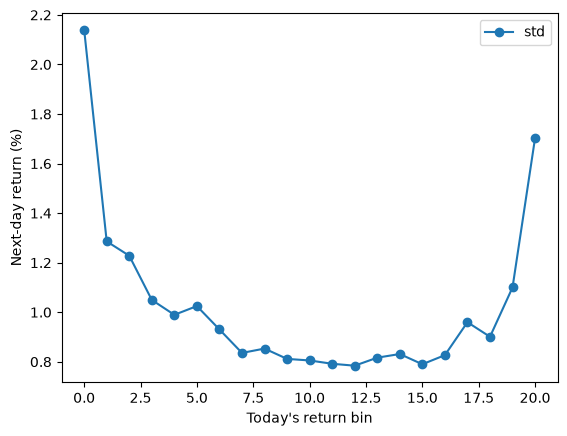

In [35]:
df['market_return_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('current value', observed=False)['market_return_tp1'].agg(['std']).plot(marker='o')
plt.ylabel("Next-day return (%)")
plt.xlabel("Today's return bin")
plt.show()

The standard deviation has a larger next day return in the extreme values, lower for the middle values.

The bins show there is a relationship between current and next day returns, but it is hard to predict from current bin because of the variation and average of zero.